# 🌱 Crop Recommendation System

## 1. Project Overview

The Crop Recommendation System is a Machine Learning-based project that helps recommend suitable crops based on soil nutrients and environmental conditions.

It analyzes important parameters such as Nitrogen, Phosphorus, Potassium, temperature, humidity, pH, and rainfall to predict the most suitable crop.

## 2. Problem Statement

Choosing the right crop according to soil and environmental conditions is important for agricultural productivity. This project uses Machine Learning algorithms to predict suitable crops based on the given input parameters.

## 3. Project Objectives

- To analyze soil and environmental data.
- To understand the relationship between different agricultural features.
- To implement multiple Machine Learning classification algorithms.
- To compare model performance.
- To select the best-performing model for crop prediction.

## 4. Dataset Description

- Dataset Name: Crop Recommendation Dataset
- Total Records: 2,200
- Total Features: 7
- Target Variable: Label
- Number of Crop Categories: 22

## 5. Algorithms Used

1. Decision Tree Classifier
2. Random Forest Classifier
3. Support Vector Machine (SVM)

## 6. Technologies and Libraries

- Python
- Google Colab
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Joblib

In [5]:
import pandas as pd

df = pd.read_csv('/content/Crop_recommendation.csv')

df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [6]:
# Check dataset information

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape:
(2200, 8)

Column Names:
Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [1]:
# Statistical summary of dataset

df.describe()

NameError: name 'df' is not defined

In [8]:
# Count each crop

df['label'].value_counts()


,count
label,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100


In [10]:
# Check missing values

print(df.isnull().sum())


N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [11]:
# Check duplicate rows

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


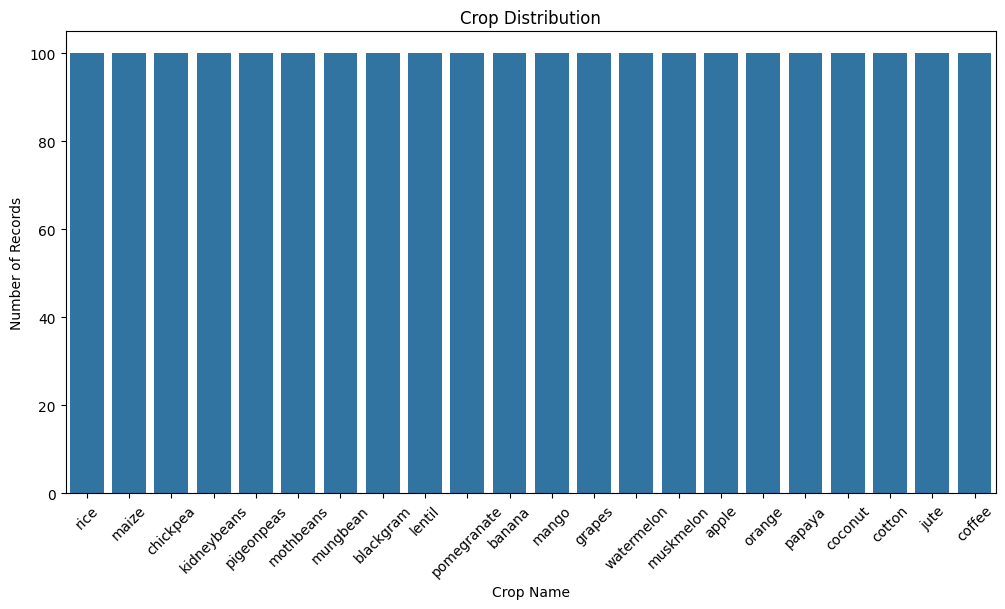

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.countplot(data=df, x='label')

plt.title("Crop Distribution")
plt.xlabel("Crop Name")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.show()

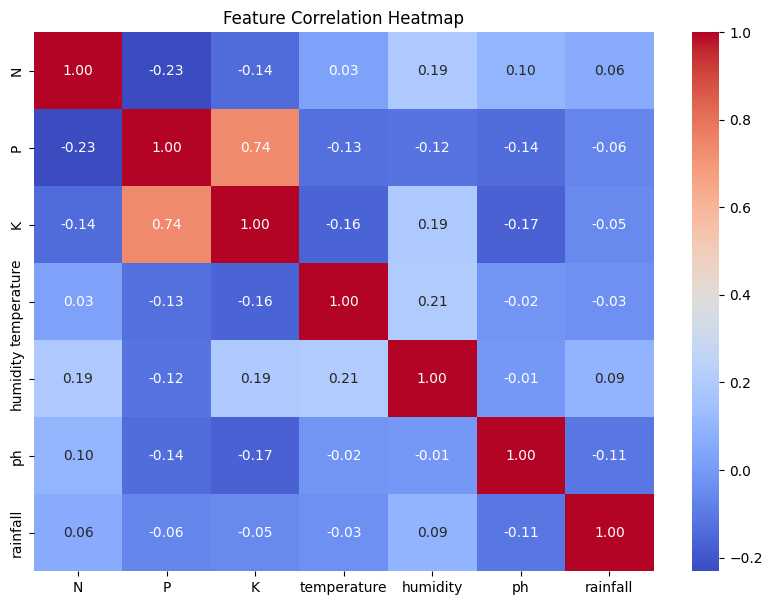

In [14]:
plt.figure(figsize=(10, 7))

correlation = df.drop(columns=['label']).corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Feature Correlation Heatmap")
plt.show()


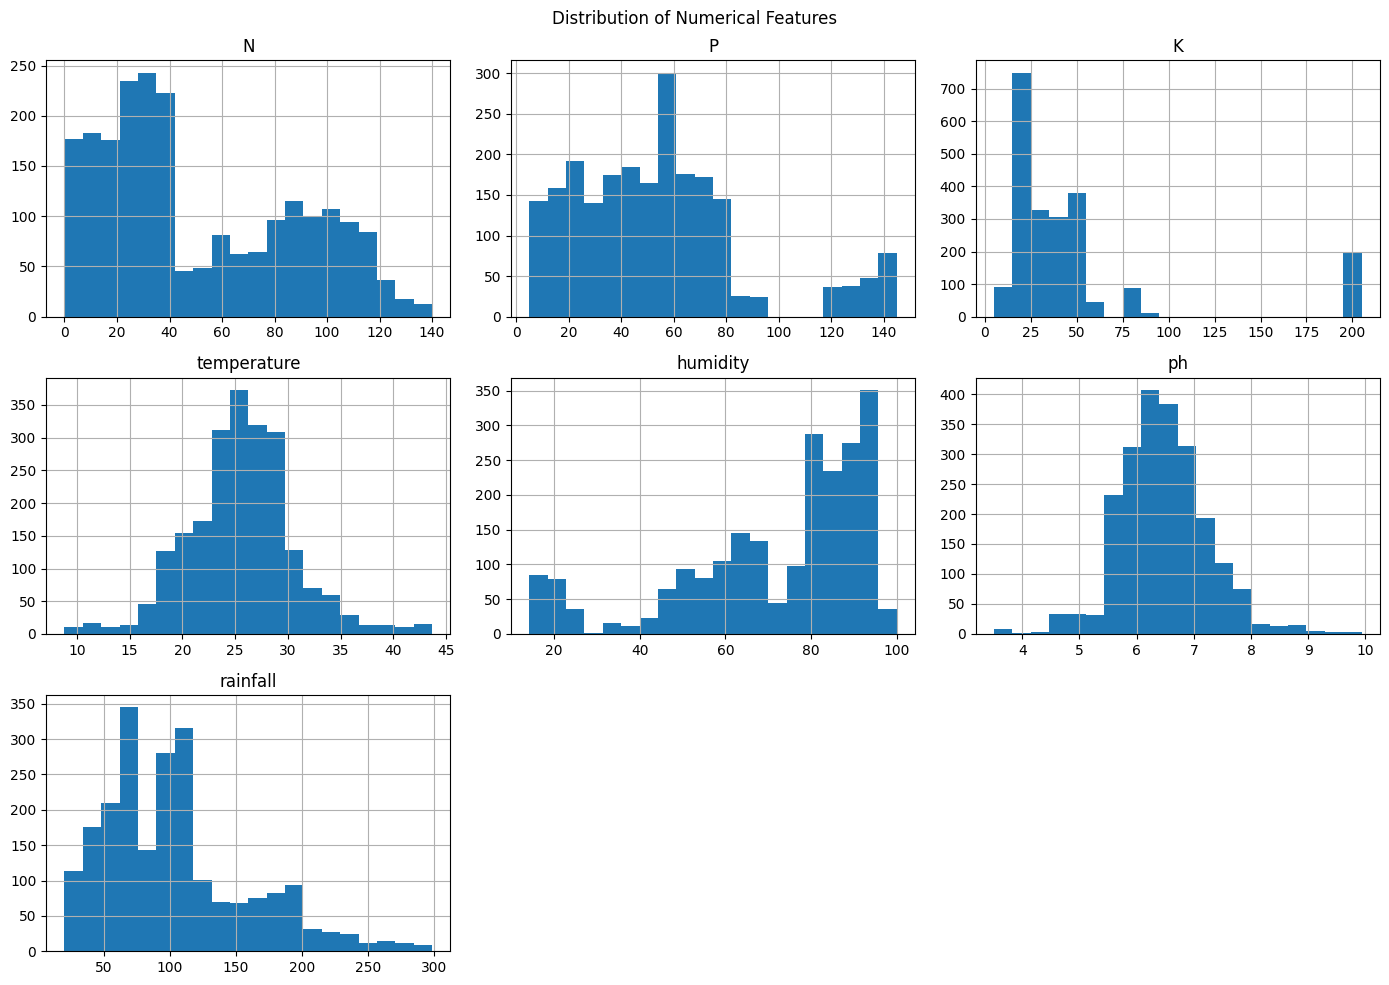

In [15]:
import matplotlib.pyplot as plt

df.hist(figsize=(14, 10), bins=20)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()


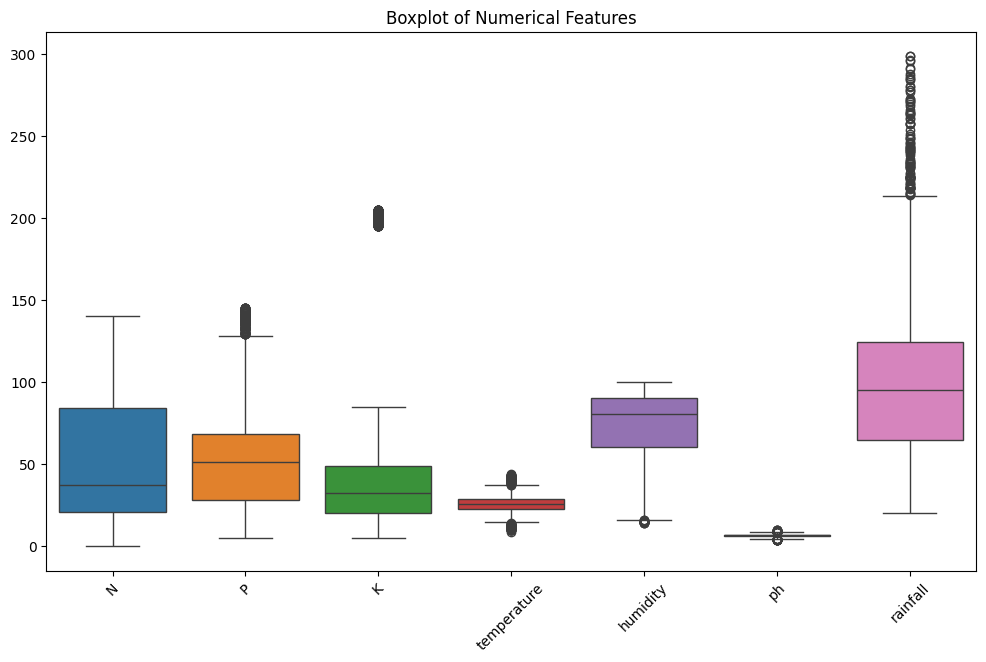

In [16]:
plt.figure(figsize=(12, 7))

sns.boxplot(data=df.drop(columns=['label']))

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)

plt.show()

In [17]:
# Separate input features and target

X = df.drop('label', axis=1)
y = df['label']

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())


Features (X):
    N   P   K  temperature   humidity        ph    rainfall
0  90  42  43    20.879744  82.002744  6.502985  202.935536
1  85  58  41    21.770462  80.319644  7.038096  226.655537
2  60  55  44    23.004459  82.320763  7.840207  263.964248
3  74  35  40    26.491096  80.158363  6.980401  242.864034
4  78  42  42    20.130175  81.604873  7.628473  262.717340

Target (y):
0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: object


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1760, 7)
Testing data: (440, 7)


In [19]:
from sklearn.tree import DecisionTreeClassifier

# Create model
dt_model = DecisionTreeClassifier(random_state=42)

# Train model
dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [20]:
from sklearn.metrics import accuracy_score

# Predict using testing data
y_pred = dt_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", accuracy * 100, "%")

Decision Tree Accuracy: 97.95454545454545 %


In [21]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.80      0.89        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.86      0.90      0.88        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.86      0.95      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

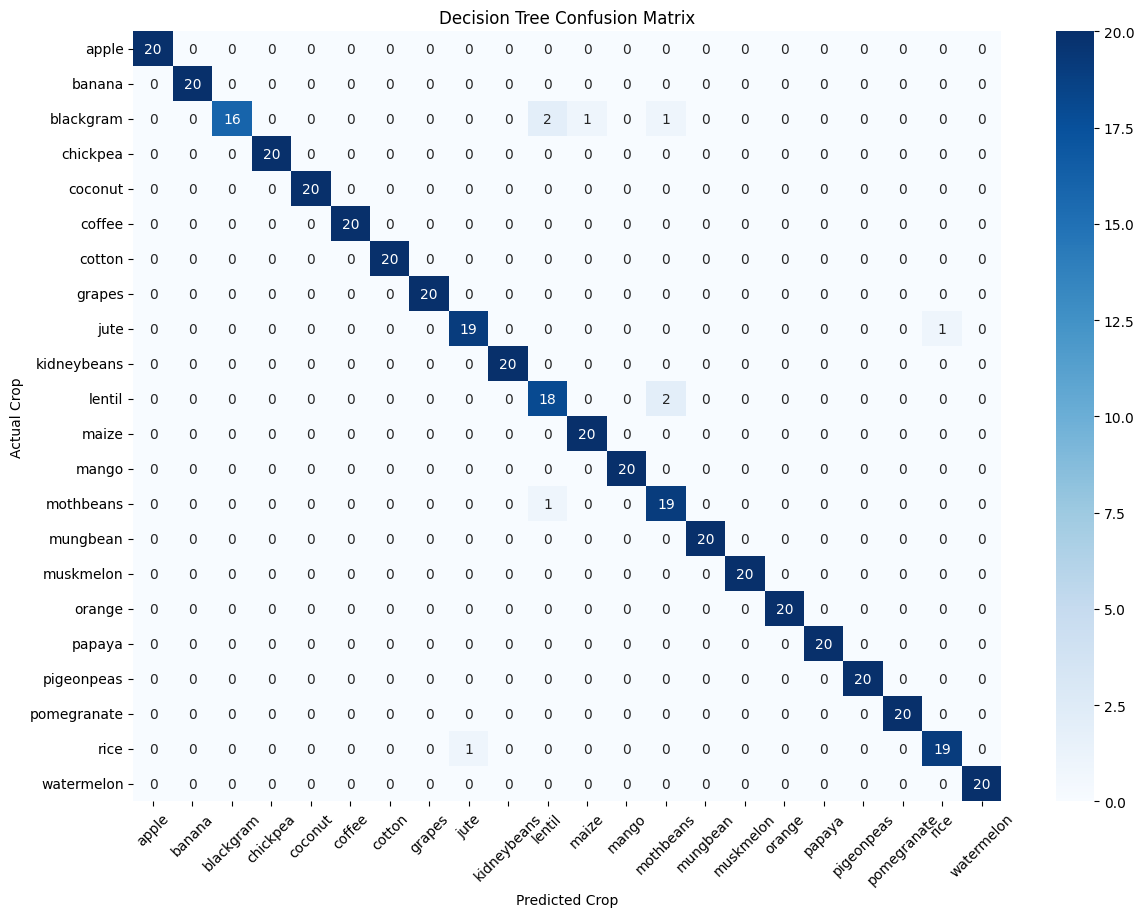

In [22]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [23]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [24]:
from sklearn.metrics import accuracy_score

# Predict using Random Forest
y_pred_rf = rf_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy * 100, "%")

Random Forest Accuracy: 99.54545454545455 %


In [25]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

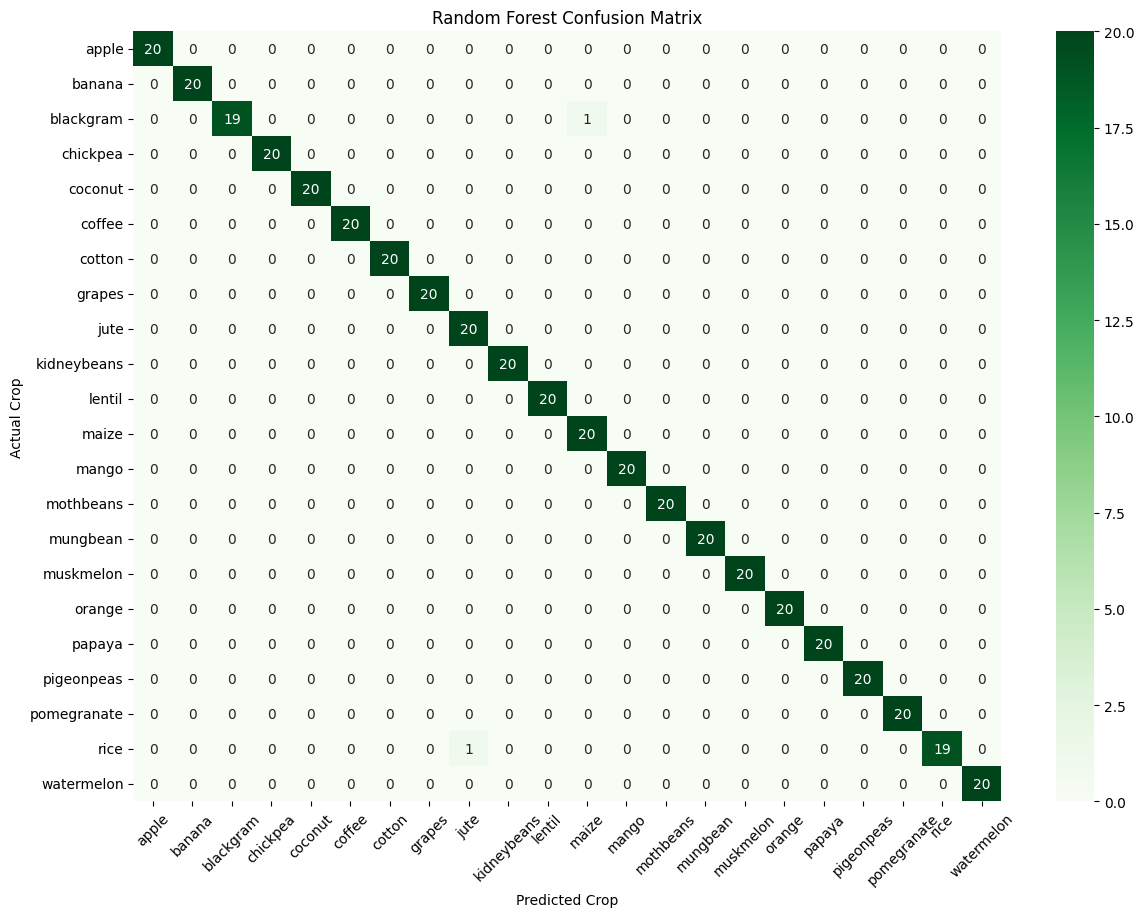

In [26]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [27]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [28]:
from sklearn.svm import SVC

# Create SVM model
svm_model = SVC(kernel='rbf')

# Train model
svm_model.fit(X_train_scaled, y_train)

print("SVM Model Trained Successfully!")

SVM Model Trained Successfully!


In [29]:
from sklearn.metrics import accuracy_score

# Predict using SVM
y_pred_svm = svm_model.predict(X_test_scaled)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy * 100, "%")

SVM Accuracy: 98.4090909090909 %


In [30]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       0.91      1.00      0.95        20
      grapes       1.00      1.00      1.00        20
        jute       0.87      1.00      0.93        20
 kidneybeans       0.95      1.00      0.98        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      0.90      0.95        20
       mango       0.95      1.00      0.98        20
   mothbeans       1.00      0.95      0.97        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

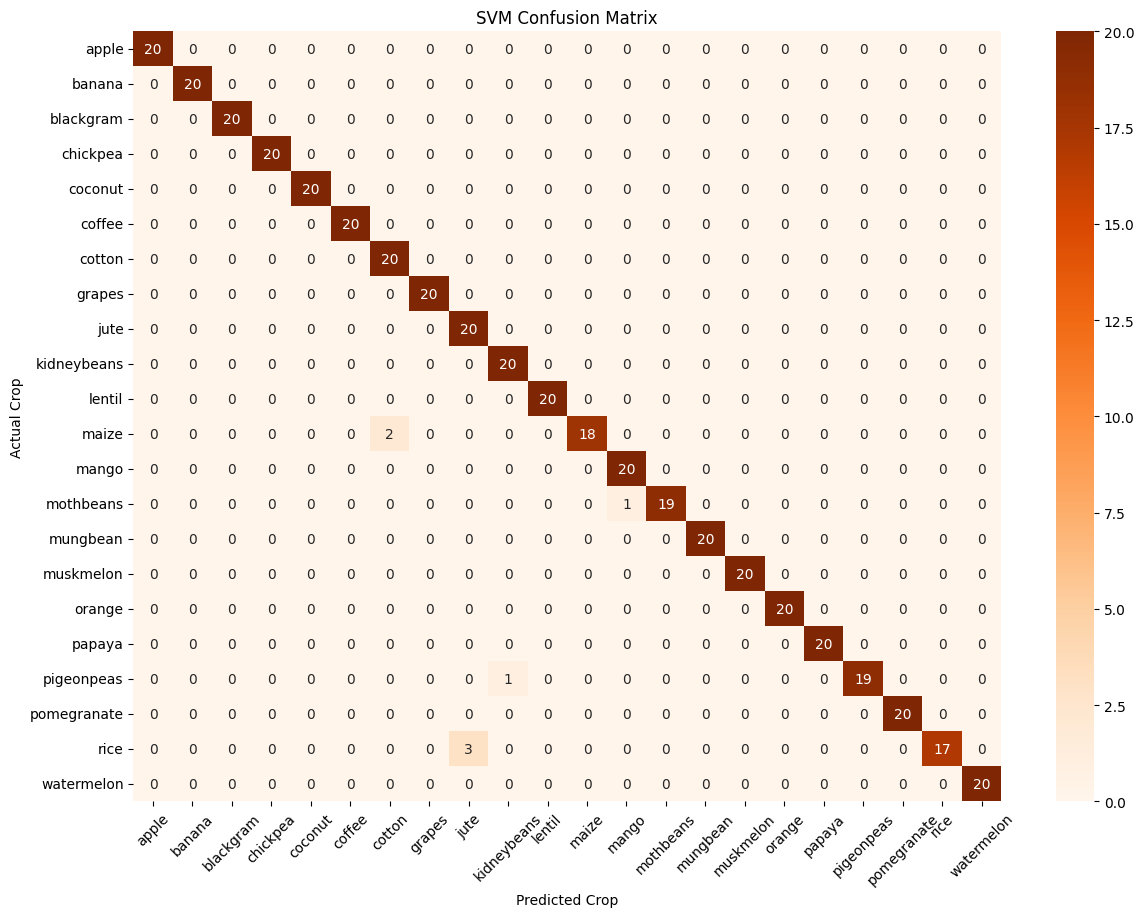

In [31]:
from sklearn.metrics import confusion_matrix

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

       Algorithm   Accuracy
0  Decision Tree  97.954545
1  Random Forest  99.545455
2            SVM  98.409091


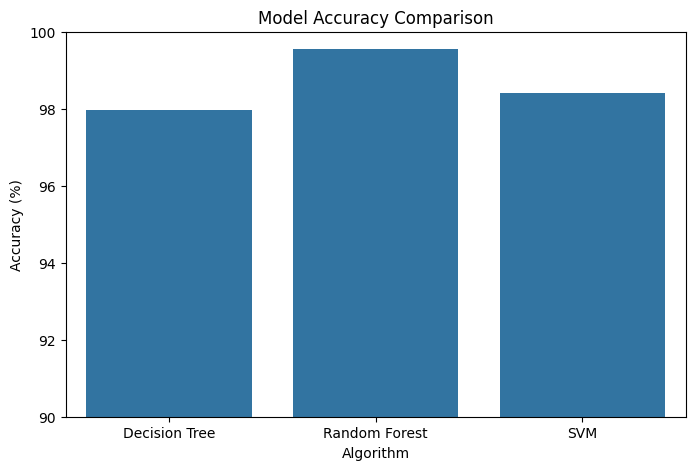

In [32]:
# Compare all three models

results = pd.DataFrame({
    'Algorithm': ['Decision Tree', 'Random Forest', 'SVM'],
    'Accuracy': [
        accuracy * 100,
        rf_accuracy * 100,
        svm_accuracy * 100
    ]
})

print(results)

# Accuracy comparison graph
plt.figure(figsize=(8, 5))

sns.barplot(data=results, x='Algorithm', y='Accuracy')

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(90, 100)

plt.show()

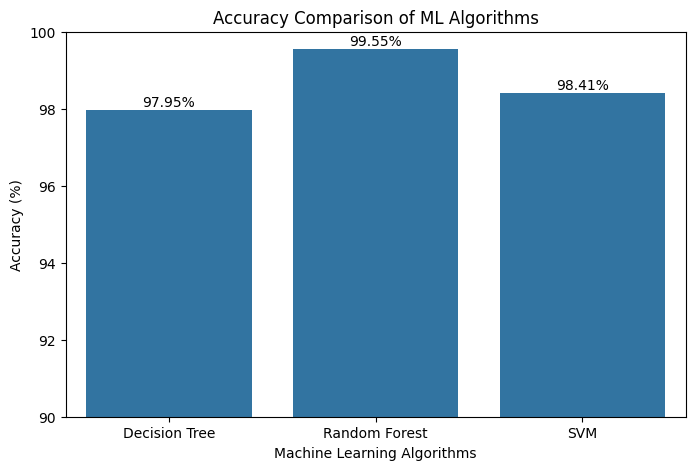

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Algorithm',
    y='Accuracy'
)

plt.title("Accuracy Comparison of ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy (%)")
plt.ylim(90, 100)

for i, value in enumerate(results['Accuracy']):
    plt.text(i, value + 0.1, f'{value:.2f}%', ha='center')

plt.show()

In [34]:
# New soil and weather conditions

new_data = pd.DataFrame({
    'N': [90],
    'P': [42],
    'K': [43],
    'temperature': [20.87],
    'humidity': [82.00],
    'ph': [6.50],
    'rainfall': [202.93]
})

# Predict crop
prediction = rf_model.predict(new_data)

print("Recommended Crop:", prediction[0])

Recommended Crop: rice


In [35]:
import joblib

# Save the best model
joblib.dump(rf_model, 'crop_recommendation_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [36]:
from google.colab import files

files.download('crop_recommendation_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

       Feature  Importance
6     rainfall    0.230184
4     humidity    0.224227
2            K    0.175393
1            P    0.150850
0            N    0.096363
3  temperature    0.072375
5           ph    0.050608


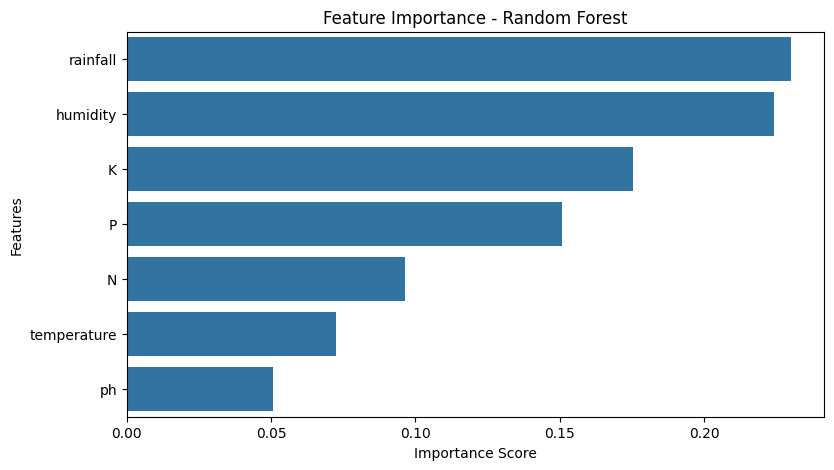

In [38]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()